In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

## **1. Cleaning columns** 
Helper functions to clean candidate names and convert age, total assets, liabilities into numeric form in data

In [128]:
def clean_candidate(name):
    if not isinstance(name, str):
        return name

    prefixes = r'^(?:(?:Adv|Dr|Mr|Mrs|Ms|Shri|Smt|Prof)\.?\s+)+'
    name = re.sub(prefixes, "", name, flags=re.IGNORECASE)

    lineage_field = r'\s+(?:S/o|D/o|W/o|C/o|H/o|@)\.?\s+.*$'
    name = re.sub(lineage_field, "", name, flags=re.IGNORECASE)

    name = name.split(",", 1)[0]
    name = name.split("(", 1)[0]
    name = name.replace(".", " ")

    words = name.split()
    words = [word.capitalize() for word in words]
    return " ".join(words)

In [129]:
def clean_age(age):
    age = pd.to_numeric(age, errors="coerce")
    return int(age) if pd.notna(age) else -1

In [130]:
def clean_money(money):
    amount = re.search(r'(?<=Rs[.\s])([\d,]+)', money)
    if amount:
        amount = amount.group(1)
    else:
        return -1

    return int(amount.replace(",",""))

In [131]:
andhra_14 = pd.read_csv("ocr_data/andhra_2014.csv")
andhra_14.head()

,Sno.,Candidate,Party,Criminal Cases,Education,Age,Total Assets,Liabilities
0,1,Abburi Koteswara Rao,Pyramid Party of India,0,10th Pass,49,"Rs 1,76,20,000\r\n~ 1 Crore+","Rs 38,00,000\r\n~ 38 Lacs+"
1,2,Abdul Waheed Shaik,INC,0,10th Pass,44,"Rs 76,54,500\r\n~ 76 Lacs+","Rs 70,00,000\r\n~ 70 Lacs+"
2,3,Adala Prabhakara Reddy,TDP,0,12th Pass,64,"Rs 1,28,25,85,640\r\n~ 128 Crore+","Rs 13,16,46,350\r\n~ 13 Crore+"
3,4,Aithabathula Jogeswara Venkata Butchi Maheswar...,INC,1,Post Graduate,63,"Rs 1,26,25,844\r\n~ 1 Crore+","Rs 25,04,500\r\n~ 25 Lacs+"
4,5,Akki Reddy Bhimanadula,Pyramid Party of India,0,10th Pass,33,"Rs 6,44,500\r\n~ 6 Lacs+",Rs 0\r\n~


**Dtypes check before Cleaning**

In [132]:
andhra_14.dtypes

Sno.               int64
Candidate         object
Party             object
Criminal Cases     int64
Education         object
Age               object
Total Assets      object
Liabilities       object
dtype: object

In [133]:
andhra_14["Candidate"] = andhra_14["Candidate"].apply(clean_candidate)
andhra_14["Age"] = andhra_14["Age"].apply(clean_age)
andhra_14["Total Assets"] = andhra_14["Total Assets"].apply(clean_money)
andhra_14["Liabilities"] = andhra_14["Liabilities"].apply(clean_money)

**Dtypes after Cleaning**

In [134]:
andhra_14.dtypes

Sno.               int64
Candidate         object
Party             object
Criminal Cases     int64
Education         object
Age                int64
Total Assets       int64
Liabilities        int64
dtype: object

In [135]:
datasets = [
    ("andhra", 2014),
    ("andhra", 2019),
    ("andhra", 2024),
    ("bihar", 2014),
    ("bihar", 2019),
    ("bihar", 2024),
    ("gujarat", 2014),
    ("gujarat", 2019),
    ("gujarat", 2024),
]

numeric_column = {"Age", "Total Assets", "Liabilities"}

def is_missing_value(series, column_name):
    missing = series.isna()
    if column_name in numeric_column:
        numeric_values = pd.to_numeric(series, errors="coerce")
        missing = missing | numeric_values.eq(-1)
    else:
        missing = missing | series.astype(str).str.strip().eq("")
    return missing

cleaned_frames = {}

for state, year in datasets:
    file_key = f"{state}_{year}"
    df = pd.read_csv(f"ocr_data/{file_key}.csv")

    df["Candidate"] = df["Candidate"].apply(clean_candidate)
    df["Age"] = df["Age"].apply(clean_age)
    df["Total Assets"] = df["Total Assets"].apply(clean_money)
    df["Liabilities"] = df["Liabilities"].apply(clean_money)
    cleaned_frames[file_key] = df

print(f"Loaded and cleaned {len(cleaned_frames)} datasets in memory.")
print(f"Imputed files will be saved directly to: cleaned_data/imputed_parquet/")

Loaded and cleaned 9 datasets in memory.
Imputed files will be saved directly to: cleaned_data/imputed_parquet/


In [136]:
for file_key, frame in cleaned_frames.items():
    print(f'\n{file_key}')
    print(f'Rows: {len(frame)}')
    print(f'Columns: {frame.columns.tolist()}')


andhra_2014
Rows: 329
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

andhra_2019
Rows: 314
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

andhra_2024
Rows: 450
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

bihar_2014
Rows: 605
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

bihar_2019
Rows: 619
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

bihar_2024
Rows: 496
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

gujarat_2014
Rows: 333
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

gujarat_2019
Rows: 371
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Case

In [137]:
# for file in cleaned_frames:
#     df = cleaned_frames[file]
#     df.to_parquet(f"cleaned_data/cleaned_raw_data//{file}.parquet", index=False)

## **2. Removing Duplicates in Data**

In [138]:
import itertools
from rapidfuzz.distance import JaroWinkler
def std_name(s):
    s = s.lower()
    s = re.sub(r"\.", " ", s)
    splitted = s.split()
    cleaned_words = [i for i in splitted]
    return " ".join(cleaned_words)


def names_agree(a, b):
    words_a = a.split()
    words_b = b.split()
    if len(words_a) <= len(words_b):
        short, long = words_a, words_b
    else:
        short, long = words_b, words_a

    def words_match(w1, w2):
        if len(w1) == 1 or len(w2) == 1:
            return w1[0] == w2[0]
        return JaroWinkler.similarity(w1, w2) >= 0.85

    for perm in itertools.permutations(long, len(short)):
        if all(words_match(s, l) for s, l in zip(short, perm)):
            return True
    return False


def find_dups(df: pd.DataFrame):
    sorted_df = df.sort_values(by="Age")
    sorted_df['Candidate'] = sorted_df['Candidate'].apply(std_name)
    sorted_df['Party'] = sorted_df['Party'].apply(std_name)
    sorted_df['Education'] = sorted_df['Education'].apply(std_name)
    n = len(sorted_df)

    dup_pairs = []

    for i in range(n):
        row_i = sorted_df.iloc[i]
        id_i = row_i['Sno.']
        for j in range(i+1,n):
            row_j = sorted_df.iloc[j]
            if abs(row_j['Age']-row_i['Age']) > 1:
                break
            if row_j['Criminal Cases']!=row_i['Criminal Cases']:
                continue
            if row_j['Party']!=row_i['Party']:
                continue
            if not names_agree(row_i['Candidate'],row_j['Candidate']):
                continue
            id_j = row_j['Sno.']
            dup_pairs.append((int(id_i)-1,int(id_j)-1))

    return dup_pairs

In [139]:
dups = find_dups(cleaned_frames['andhra_2014'])
print(dups)

[(65, 66)]


In [140]:
cleaned_frames["andhra_2014"].drop(65, inplace=True)

In [141]:
dups = find_dups(cleaned_frames['andhra_2019'])
print(dups)

[(249, 257), (79, 243), (87, 88)]


In [142]:
cleaned_frames["andhra_2019"].drop(87, inplace=True)

In [143]:
dups = find_dups(cleaned_frames['andhra_2024'])
print(dups)

[(150, 39), (431, 430), (315, 418)]


In [144]:
cleaned_frames["andhra_2024"].drop(430, inplace=True)

In [145]:
dups = find_dups(cleaned_frames['bihar_2014'])
print(dups)

[(593, 589), (441, 388)]


In [146]:
dups_ = find_dups(cleaned_frames['bihar_2019'])
print(dups_)

[(360, 374), (284, 225), (590, 591), (587, 588)]


In [147]:
cleaned_frames['bihar_2019'].drop(index=[591,588], inplace=True)

In [148]:
dups__ = find_dups(cleaned_frames['bihar_2024'])
print(dups__)

[(361, 362), (3, 38), (475, 476), (470, 471), (51, 52)]


In [149]:
cleaned_frames['bihar_2024'].iloc[361]

Sno.                       362
Candidate         Ranjan Kumar
Party                      IND
Criminal Cases               0
Education             Graduate
Age                         28
Total Assets           6107000
Liabilities                  0
Name: 361, dtype: object

In [150]:
cleaned_frames['bihar_2024'].iloc[362]

Sno.                       363
Candidate         Ranjan Kumar
Party                      IND
Criminal Cases               0
Education            12th Pass
Age                         29
Total Assets           1632000
Liabilities                  0
Name: 362, dtype: object

In [151]:
cleaned_frames['bihar_2024'].drop(index=[475,470], inplace=True)

In [152]:
dup_guj = find_dups(cleaned_frames['gujarat_2014'])
print(dup_guj)

[(247, 246)]


In [153]:
cleaned_frames['gujarat_2014'].drop(246, inplace=True)

In [154]:
dup_guj_ = find_dups(cleaned_frames['gujarat_2019'])
print(dup_guj_)

[(294, 256), (256, 254), (36, 35), (86, 85), (173, 7)]


In [155]:
cleaned_frames['gujarat_2019'].iloc[254:257]

,Sno.,Candidate,Party,Criminal Cases,Education,Age,Total Assets,Liabilities
254,255,Rajeshbhai Solanki,IND,0,12th Pass,37,246000,0
255,256,Raju Parmar,INC,0,Graduate,68,262997727,18943977
256,257,Rakeshbhai,IND,0,10th Pass,37,801500,0


In [156]:
cleaned_frames['gujarat_2019'].drop(index=[35,85], inplace=True)

In [157]:
dup_guj__ = find_dups(cleaned_frames['gujarat_2024'])
print(dup_guj__)

[(174, 173)]


In [158]:
cleaned_frames['gujarat_2024'].drop(173, inplace=True)

## **3. Imputation**

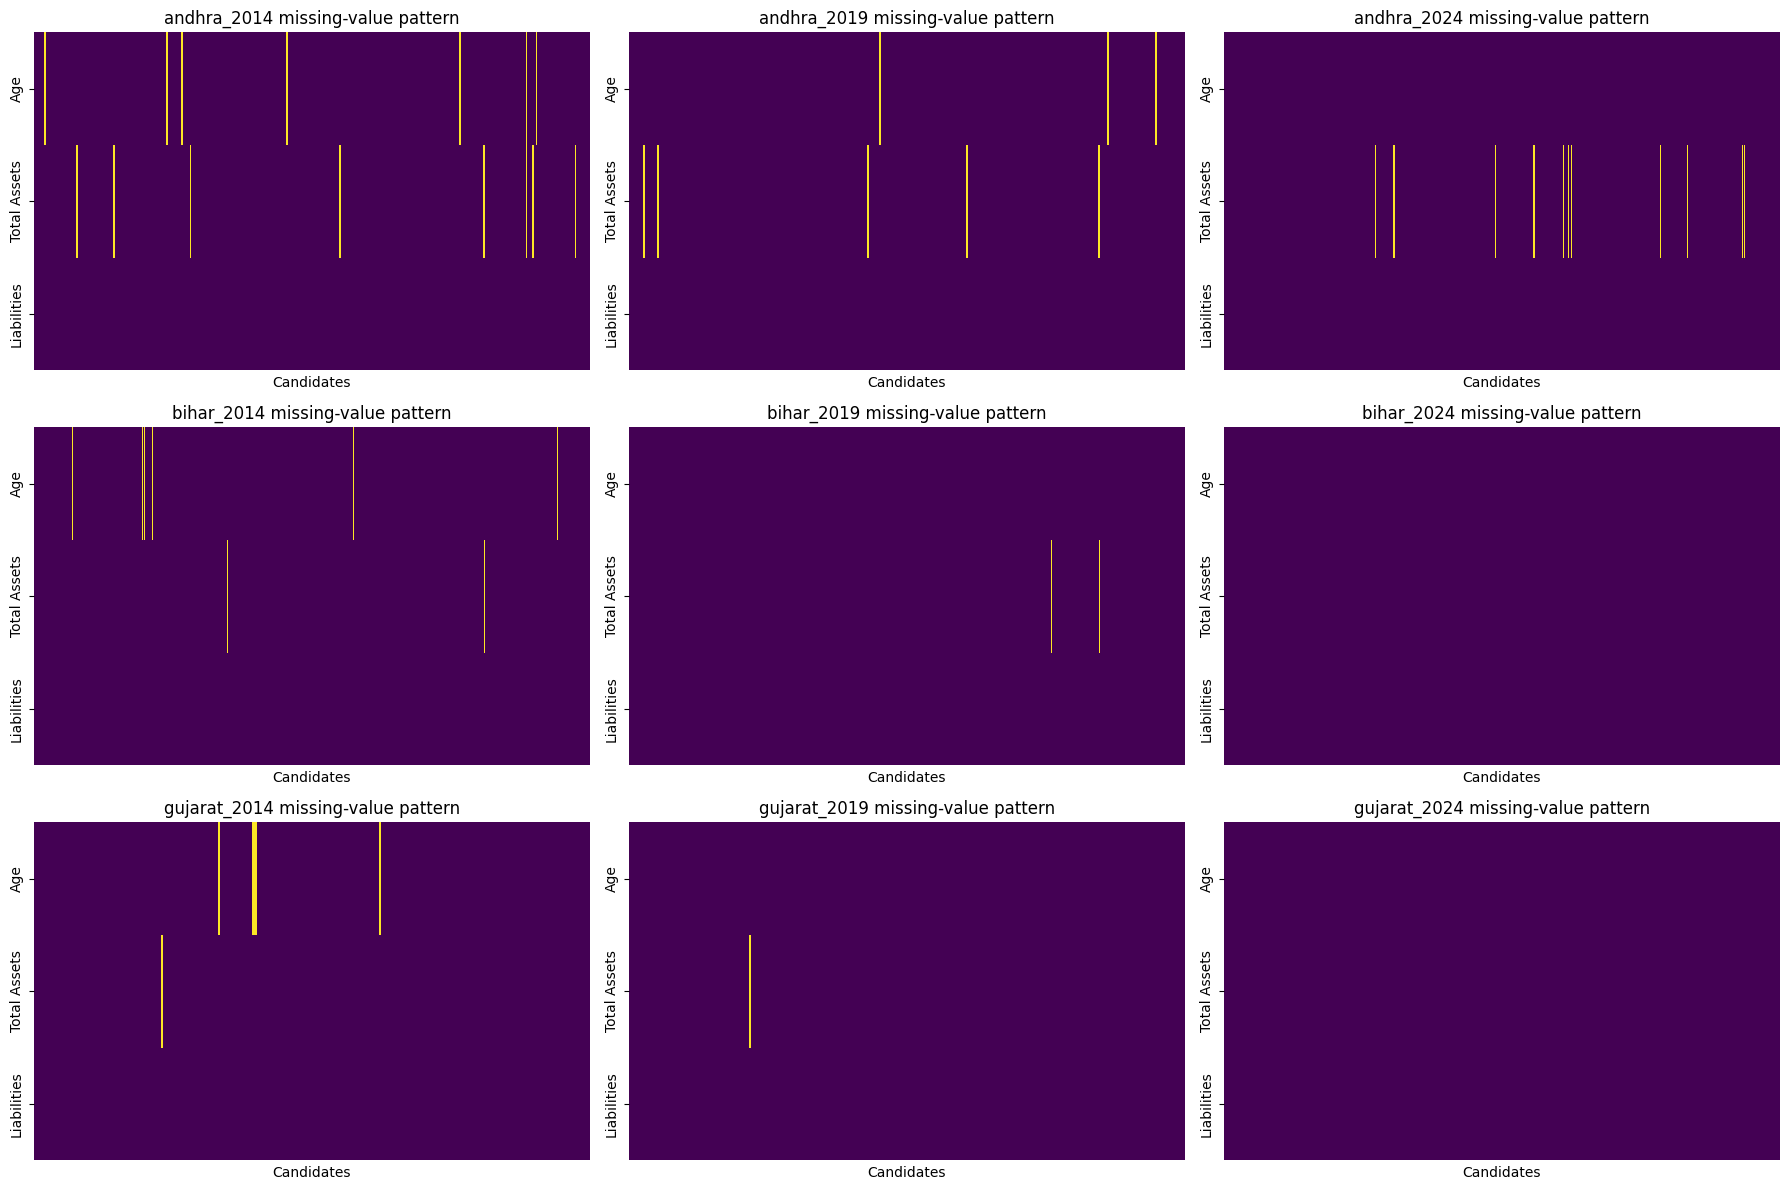

In [159]:
columns_to_show = ["Age", "Total Assets", "Liabilities"]
fig, axes = plt.subplots(3, 3, figsize=(18, 12), squeeze=False,)

for axis in axes.flat:
    axis.set_visible(False)

for axis, (path, df) in zip(axes.flat, cleaned_frames.items()):
    missing_data = pd.DataFrame(index=df.index)

    for column in columns_to_show:
        values = pd.to_numeric(df[column], errors="coerce")
        missing_data[column] = values.isna() | values.eq(-1)

    axis.set_visible(True)
    sns.heatmap(missing_data.T, ax=axis, cmap="viridis", vmin=0, vmax=1,
                cbar=False, xticklabels=False, yticklabels=True,)

    axis.set_title(f"{path} missing-value pattern")
    axis.set_xlabel("Candidates")
    axis.set_ylabel("")

fig.tight_layout()
plt.show()

In [160]:
numeric_cols_to_impute = ["Age","Total Assets","Liabilities",]

imputed_frames = {}

for path, df in cleaned_frames.items():
    df_imputed = df.copy()

    for col in numeric_cols_to_impute:
        if col not in df_imputed.columns:
            continue

        values = pd.to_numeric(df_imputed[col], errors="coerce")
        values = values.mask(values == -1)
        missing_count = int(values.isna().sum())

        if missing_count == 0:
            print(f"{path}: no missing values in {col}")
            continue

        if values.notna().sum() == 0:
            print(f"{path}: cannot impute {col}; no valid values for its median")
            continue

        median_value = values.median()
        df_imputed[col] = values.fillna(median_value)

        print(
            f"{path}: imputed {missing_count} values in {col} "
            f"with median {median_value:.2f}"
        )
    imputed_frames[path] = df_imputed
    df_imputed.to_parquet(f"cleaned_data/imputed_parquet/{path}_imputed.parquet", index=False)
print(f"Saved {len(imputed_frames)} imputed datasets to cleaned_data/imputed_parquet/")

andhra_2014: imputed 7 values in Age with median 46.00
andhra_2014: imputed 8 values in Total Assets with median 2910881.00
andhra_2014: no missing values in Liabilities
andhra_2019: imputed 3 values in Age with median 48.00
andhra_2019: imputed 5 values in Total Assets with median 5060272.00
andhra_2019: no missing values in Liabilities
andhra_2024: no missing values in Age
andhra_2024: imputed 11 values in Total Assets with median 2327339.00
andhra_2024: no missing values in Liabilities
bihar_2014: imputed 6 values in Age with median 45.00
bihar_2014: imputed 2 values in Total Assets with median 3490200.00
bihar_2014: no missing values in Liabilities
bihar_2019: no missing values in Age
bihar_2019: imputed 2 values in Total Assets with median 4171200.00
bihar_2019: no missing values in Liabilities
bihar_2024: no missing values in Age
bihar_2024: no missing values in Total Assets
bihar_2024: no missing values in Liabilities
gujarat_2014: imputed 5 values in Age with median 48.00
gujar

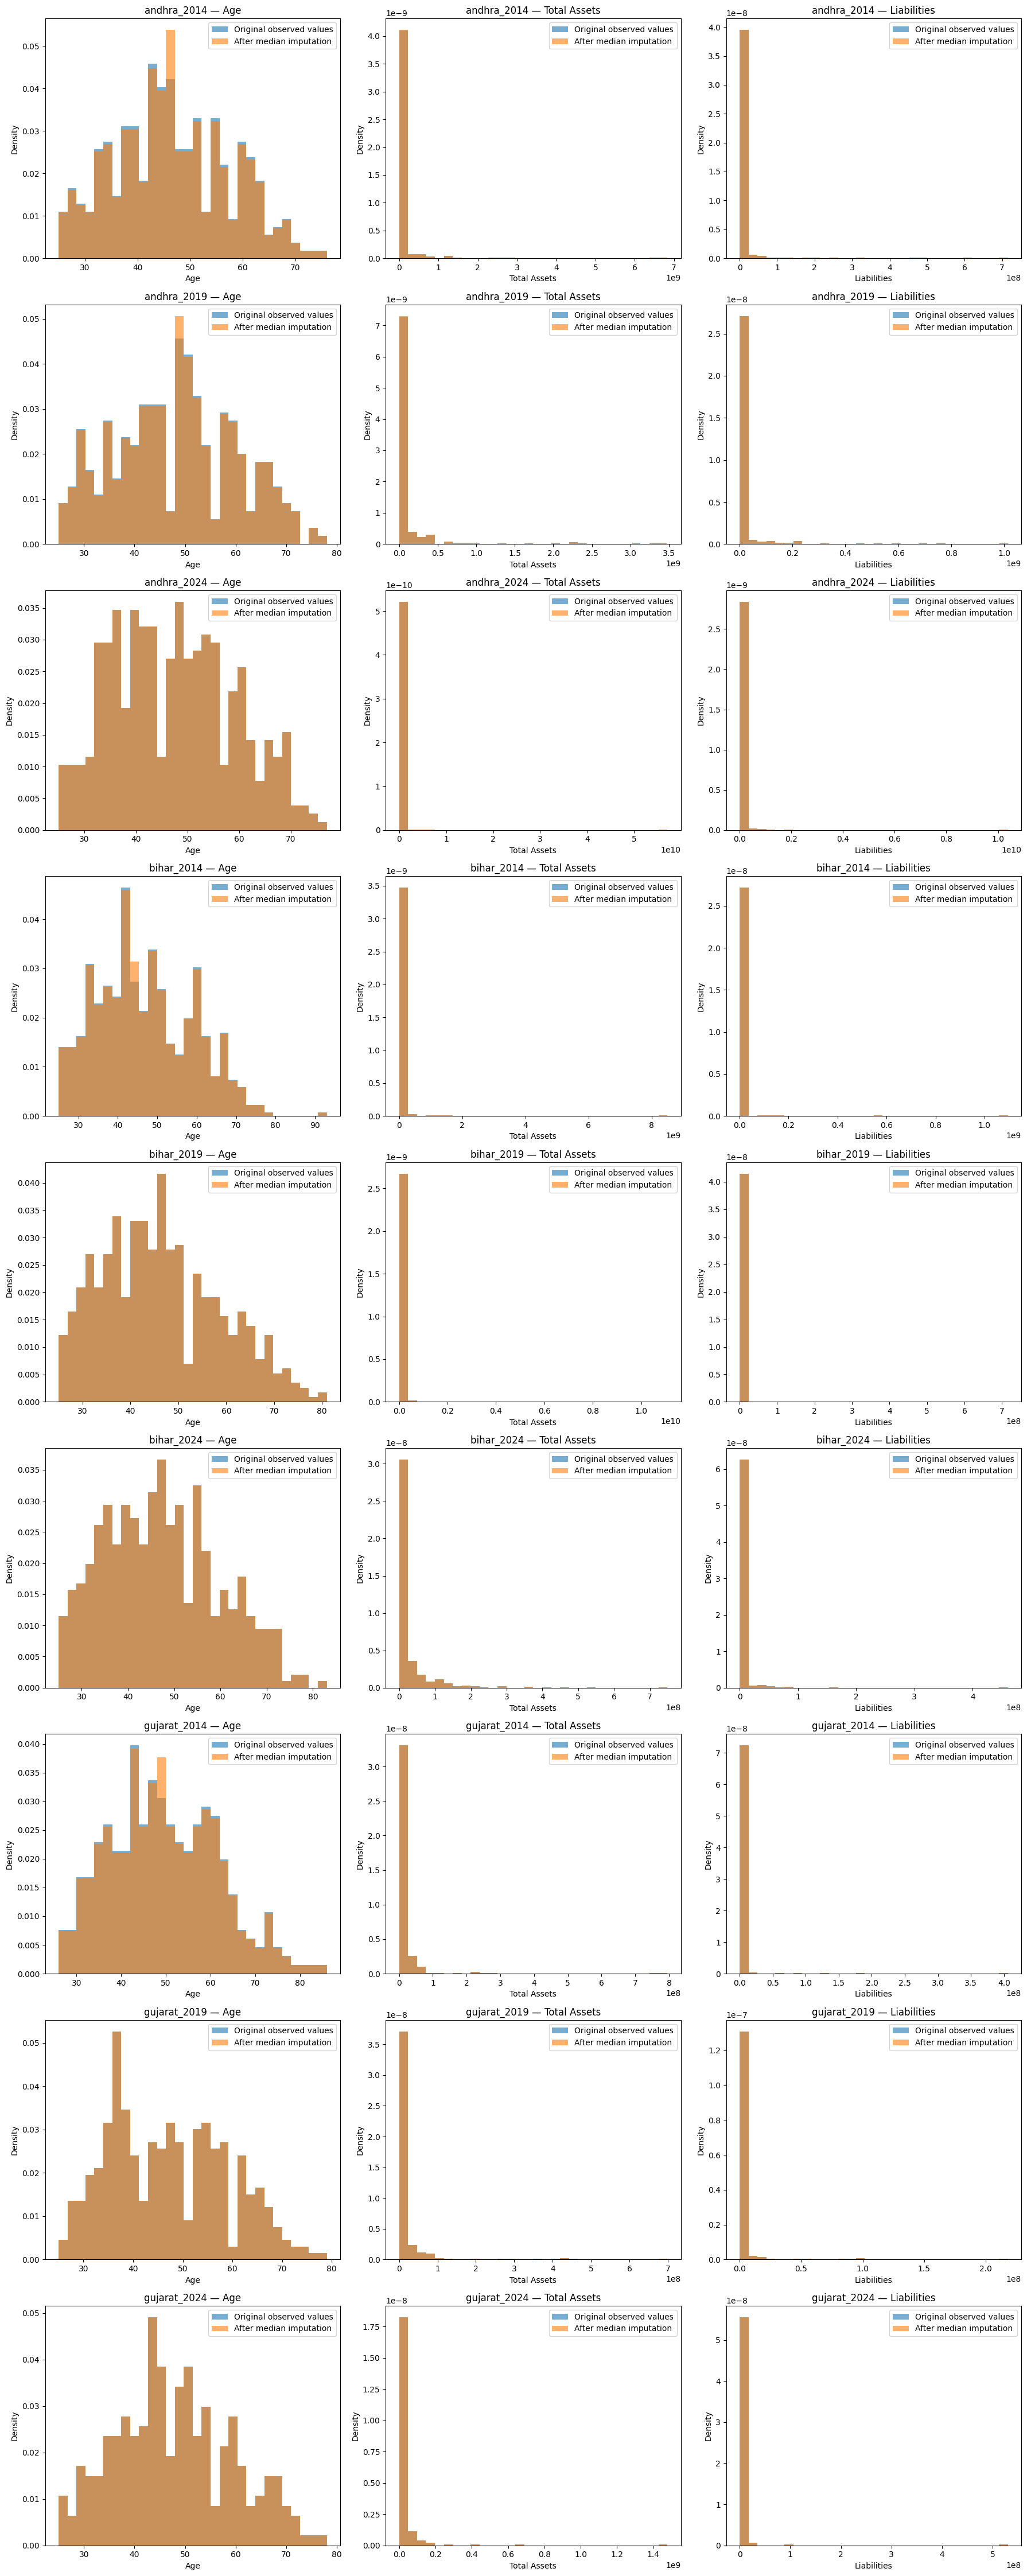

In [161]:
file_items = list(cleaned_frames.items())

n_rows = len(file_items)
n_cols = len(numeric_cols_to_impute)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 45), squeeze=False)

for row_index, (input_path, original_df) in enumerate(file_items):
    imputed_path = f'cleaned_data/imputed_parquet/{input_path}_imputed.parquet'
    imputed_df = pd.read_parquet(imputed_path)

    for column_index, column in enumerate(numeric_cols_to_impute):
        axis = axes[row_index, column_index]

        if column not in original_df.columns or column not in imputed_df.columns:
            axis.set_title(f'{input_path} — {column} (column not found)')
            axis.set_axis_off()
            continue

        original_values = pd.to_numeric(original_df[column],errors='coerce')
        original_values = original_values.mask(original_values.eq(-1)).dropna()

        imputed_values = pd.to_numeric(imputed_df[column],errors='coerce')
        imputed_values = imputed_values.mask(imputed_values.eq(-1)).dropna()

        if original_values.empty and imputed_values.empty:
            axis.set_title(f'{input_path} — {column} (no values)')
            axis.set_axis_off()
            continue

        if not original_values.empty:
            axis.hist(original_values, bins=30, alpha=0.6, label='Original observed values', density=True)

        if not imputed_values.empty:
            axis.hist(imputed_values, bins=30, alpha=0.6, label='After median imputation', density=True)

        axis.set_title(f'{input_path} — {column}')
        axis.set_xlabel(column)
        axis.set_ylabel('Density')
        axis.legend()

plt.tight_layout()
plt.show()

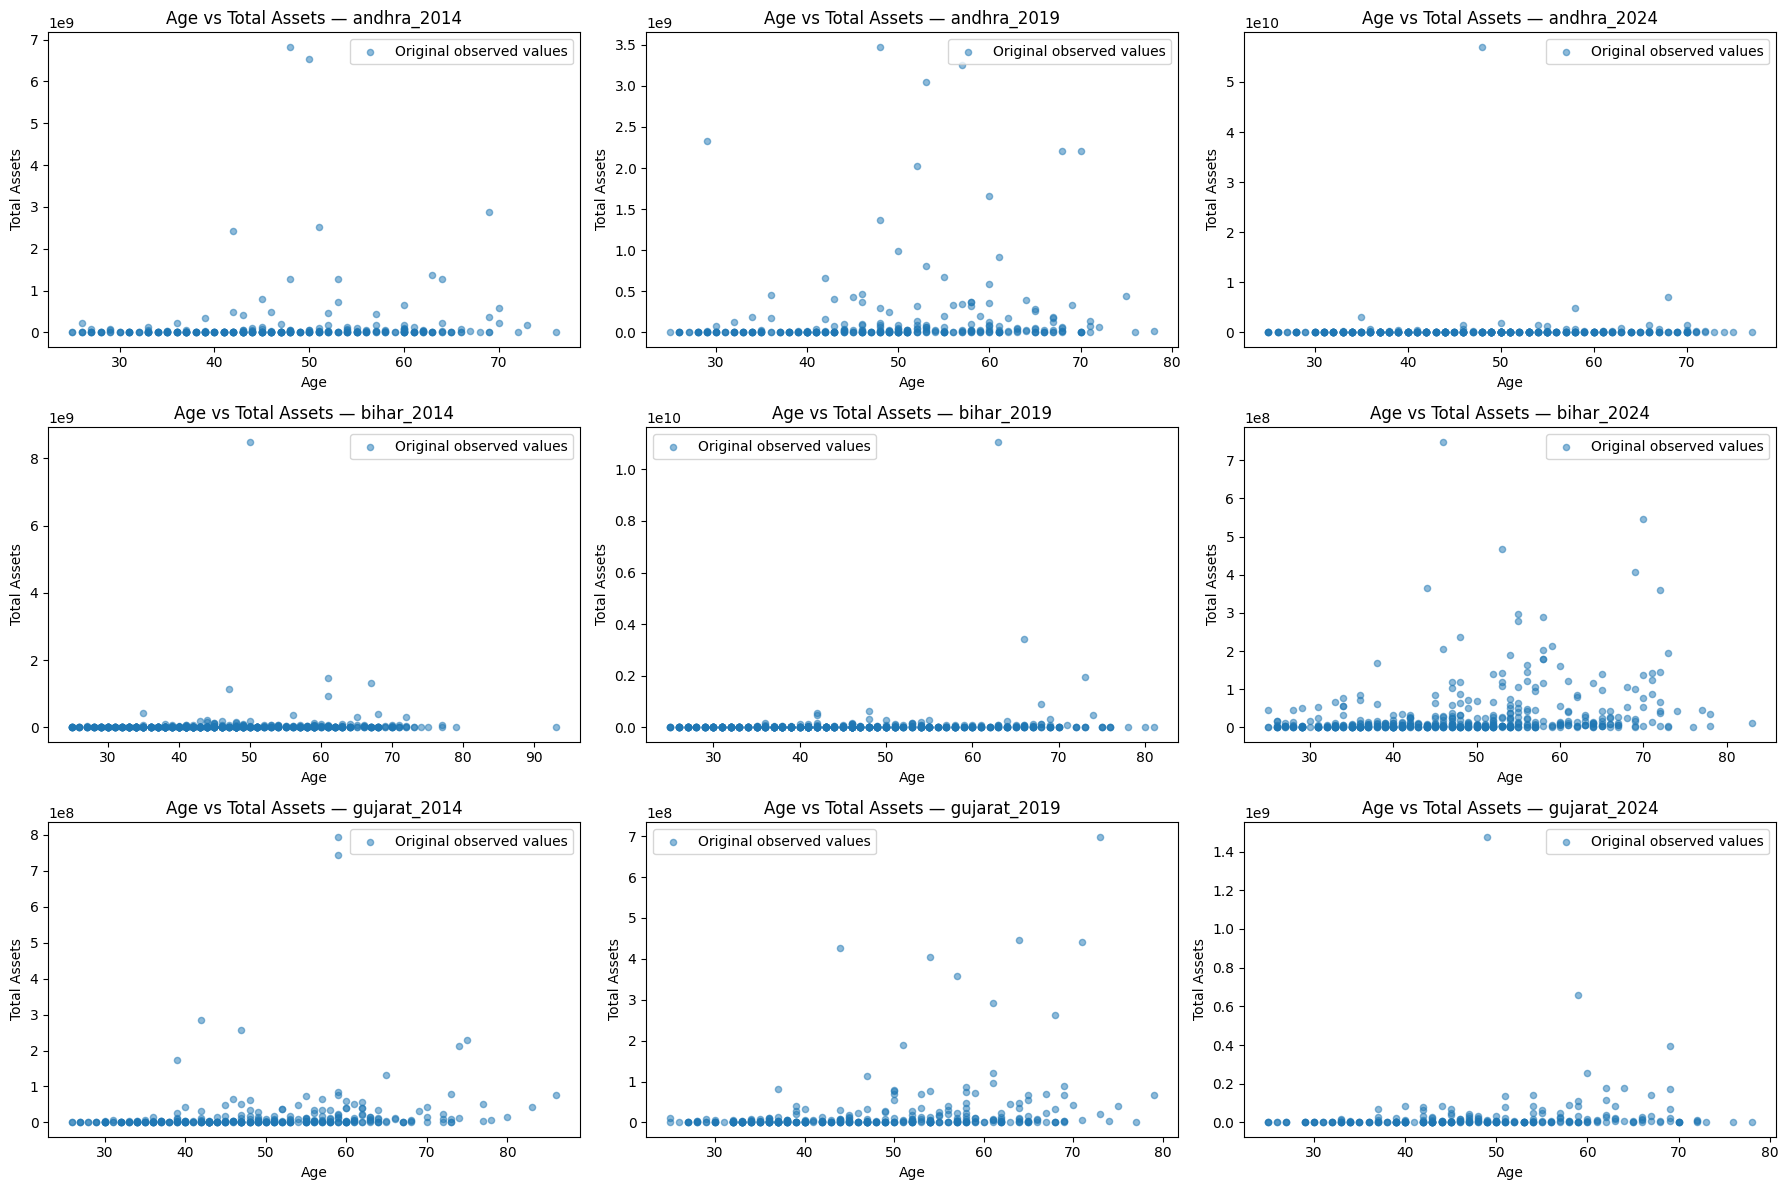

In [162]:
file_items = list(cleaned_frames.items())

fig, axes = plt.subplots(3, 3, figsize=(18, 12), squeeze=False,)

for index, (input_path, original_df) in enumerate(file_items):
    row_index = index // 3
    column_index = index % 3
    axis = axes[row_index, column_index]

    imputed_path = f'cleaned_data/imputed_parquet/{input_path}_imputed.parquet'
    imputed_df = pd.read_parquet(imputed_path)

    age_original = pd.to_numeric(original_df['Age'], errors='coerce')
    assets_original = pd.to_numeric(original_df['Total Assets'], errors='coerce')
    age_imputed = pd.to_numeric(imputed_df['Age'], errors='coerce')
    assets_imputed = pd.to_numeric(imputed_df['Total Assets'], errors='coerce')
    assets_were_missing = (original_df['Total Assets'].isna() & assets_original.eq(-1))
    age_is_available = age_imputed.notna() & age_imputed.ne(-1)
    assets_are_available = assets_imputed.notna() & assets_imputed.ne(-1)

    original_rows = (age_original.notna() & age_original.ne(-1) & assets_original.notna() & assets_original.ne(-1))
    imputed_rows = (assets_were_missing & age_is_available & assets_are_available)
    axis.scatter(age_original.loc[original_rows], assets_original.loc[original_rows], alpha=0.5, label='Original observed values', s=20)

    if imputed_rows.any():
        axis.scatter(age_imputed.loc[imputed_rows], assets_imputed.loc[imputed_rows], alpha=0.8, label='Imputed Total Assets', s=35, marker='x')

    axis.set_title(f'Age vs Total Assets — {input_path}')
    axis.set_xlabel('Age')
    axis.set_ylabel('Total Assets')
    axis.legend()

plt.tight_layout()
plt.show()